# 03 · Building the tensile-test workflow from nodes

**Goal.** Show how single analysis steps (atomic nodes) are composed into the per-specimen workflow `specimen_workflow` and into a batch over several specimens with [pyiron_workflow](https://github.com/pyiron/pyiron_workflow) and [flowrep](https://github.com/pyiron/flowrep), and how the same nodes are reused in a new workflow without copying code.

**Audience.** Workflow developers, i.e. computation-focused MSE experts who write or adapt analysis workflows.

**Prerequisites.**
- Python, and the idea of a workflow as a directed acyclic graph of function calls.
- The `pmd-demonstrator` environment from `environment.yml`, which installs the package `pmd_tensile` and Graphviz.
- `ONTODOCKER_ADDRESS` (and `ONTODOCKER_TOKEN`, if the instance needs one) set in the environment before Jupyter starts. Neither is printed here.
- What each analysis node computes is the topic of notebook 02; here the nodes are building blocks.

**Reading paths.** Workflow developers: **03** → [04](04-tensile-workflow-knowledge-graph.ipynb) → [02](02-tensile-analysis-nodes.ipynb) → [05](05-tensile-analysis-overview.ipynb). Ontologists: [01](01-tensile-data-from-graphs.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → [05](05-tensile-analysis-overview.ipynb). [Notebook 04](04-tensile-workflow-knowledge-graph.ipynb) continues from here with what semantikon records about these workflows as a knowledge graph.

*Execution class: network-read.* The notebook queries the PMDco 2 tensile-test datasets on Ontodocker and downloads curve CSV files from the public data host. It writes nothing to remote services or to the repository.

## Setup

In [1]:
import inspect
import os
import typing
import warnings

import flowrep as fr
import graphviz
import numpy as np
import pandas as pd
import pyiron_workflow as pwf
from IPython.display import display

from pmd_tensile import analysis, demo, workflows

# semantikon's provenance hashing triggers an upstream networkx notice about changed hashes.
warnings.filterwarnings("ignore", message="The hashes produced for directed graphs", category=UserWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

if not os.environ.get(demo.ONTODOCKER_ADDRESS_ENV, "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

PROFILE_ID = "pmdco2-tto"
SOURCE = {
    "kind": "ontodocker",
    "datasets": [
        "pmdco2_tto_example_parallel",
        "pmdco2_tto_example_perpendicular",
        "pmdco2_tto_example_diagonal",
    ],
}
print("Ontology profile:", PROFILE_ID)
print("Datasets:", ", ".join(SOURCE["datasets"]))

Ontology profile: pmdco2-tto
Datasets: pmdco2_tto_example_parallel, pmdco2_tto_example_perpendicular, pmdco2_tto_example_diagonal


## 1. An atomic node

An atomic node is a plain Python function with the decorator `@fr.atomic`. The decorator reads the function's signature and return statement and attaches a *recipe*: the names of the input and output ports and a reference to the function (module and name). The function itself is unchanged.

The type hints carry units and quantity kinds. `pmd_tensile.analysis` defines them with semantikon's `u()`, e.g. `ForceArray = u(np.ndarray, units="N", uri=QK_FORCE)`, where `QK_FORCE` is the QUDT quantity kind `Force`. `engineering_stress` is the smallest node of the analysis:

In [2]:
print(inspect.getsource(analysis.engineering_stress))

recipe = analysis.engineering_stress.flowrep_recipe
print(type(recipe).__name__, "| inputs:", recipe.inputs, "| outputs:", recipe.outputs)
print("function:", recipe.reference.info.module + "." + recipe.reference.info.qualname)

@fr.atomic
def engineering_stress(force_n: ForceArray, s0_mm2: AreaMM2) -> StressArray:
    """sigma = F/S0 in MPa (for display; the analysis decides in force space)."""
    stress_mpa = np.asarray(force_n, dtype=float) / _check_s0(s0_mm2)
    return stress_mpa

AtomicRecipe | inputs: ['force_n', 's0_mm2'] | outputs: ['stress_mpa']
function: pmd_tensile.analysis.engineering_stress


The units and quantity kinds are part of the type hints, so they can be read from the function without running it. The table lists them per port:

In [3]:
def port_annotations(function) -> pd.DataFrame:
    # One row per annotated port: type, unit and quantity kind from the u() metadata.
    rows = []
    for port, hint in typing.get_type_hints(function, include_extras=True).items():
        metadata = dict(zip(*[iter(hint.__metadata__[0])] * 2)) if hasattr(hint, "__metadata__") else {}
        rows.append(
            {
                "port": "output" if port == "return" else port,
                "type": getattr(typing.get_args(hint)[0] if metadata else hint, "__name__", str(hint)),
                "unit": metadata.get("units"),
                "quantity kind": str(metadata.get("uri", "")).rsplit("/", 1)[-1] or None,
            }
        )
    return pd.DataFrame(rows)


display(port_annotations(analysis.engineering_stress))

,port,type,unit,quantity kind
0,force_n,ndarray,N,Force
1,s0_mm2,float,mm**2,Area
2,output,ndarray,MPa,Stress


Because the function is unchanged, it can be called directly, e.g. in a unit test. Wrapped with `pwf.node(...)`, the same function runs as a pyiron_workflow node, which also records its inputs and outputs. Both give the same numbers:

In [4]:
force_n = np.array([0.0, 5_000.0, 10_000.0])
s0_mm2 = 20.0

direct = analysis.engineering_stress(force_n, s0_mm2)
as_node = pwf.node(analysis.engineering_stress).run(force_n=force_n, s0_mm2=s0_mm2)
print("direct call:      ", direct, "MPa")
print("pyiron_workflow:  ", as_node.outputs.stress_mpa, "MPa")
print("identical:", np.array_equal(direct, as_node.outputs.stress_mpa))

direct call:       [  0. 250. 500.] MPa
pyiron_workflow:   [  0. 250. 500.] MPa
identical: True


## 2. The per-specimen workflow `specimen_workflow`

`specimen_workflow` (in `pmd_tensile.workflows`) is an `@fr.workflow` function, a macro. flowrep parses its body: every node call becomes a child node, and every variable that is passed from one call to another becomes an edge. The body has no `for`, `while`, `if` or `try`, so the recipe is a flat directed acyclic graph. Its inputs are JSON-able values only: the profile ID, the source description, the specimen ID, an optional curve locator and the optional method parameters.

In [5]:
ROLES = {
    "pmd_tensile.exploration": "ontology-aware",
    "pmd_tensile.acquisition": "ontology-aware",
    "pmd_tensile.analysis": "ontology-agnostic analysis",
    "pmd_tensile.workflows": "ontology-agnostic adapter",
}

macro = workflows.specimen_workflow.flowrep_recipe
print("inputs: ", macro.inputs)
print("outputs:", macro.outputs)
print(f"{len(macro.nodes)} child nodes, {len(macro.edges)} edges between them, "
      f"{len(macro.input_edges)} edges from the workflow inputs")

children = pd.DataFrame(
    [
        {
            "child node": label,
            "function": node.reference.info.module + "." + node.reference.info.qualname,
            "role": ROLES.get(node.reference.info.module, "other"),
        }
        for label, node in macro.nodes.items()
    ]
)
display(children.groupby("role").size().rename("child nodes").to_frame())

inputs:  ['profile_id', 'source', 'specimen_id', 'curve_locator', 'parameters']
outputs: ['analysis', 'summary', 'comparison', 'curve_sha256', 'curve_url', 'n_samples', 'e_gpa', 'reh_mpa', 'rel_mpa', 'rp02_mpa', 'fm_n', 'rm_mpa', 'ag_percent', 'agt_percent']
24 child nodes, 86 edges between them, 8 edges from the workflow inputs


,child nodes
role,
ontology-agnostic adapter,6
ontology-agnostic analysis,15
ontology-aware,3


The drawing shows the child nodes and the data flow between them, drawn from the recipe alone. Colours give the role of the node's module: blue for the ontology-aware acquisition, green for the ontology-agnostic analysis, orange for the adapters that turn the parameters and the neutral records into annotated arrays and scalars. Grey ellipses are the workflow inputs; the 14 workflow outputs are left out for readability.

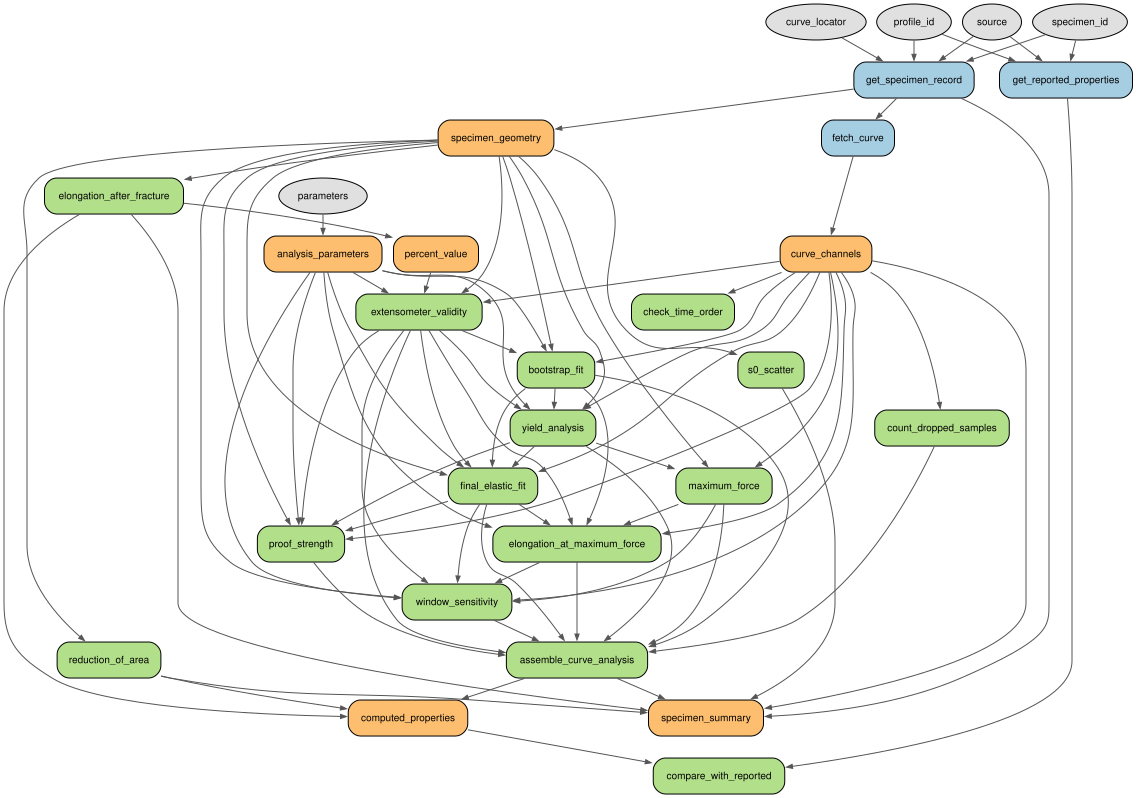

In [6]:
COLOURS = {
    "pmd_tensile.exploration": "#a6cee3",
    "pmd_tensile.acquisition": "#a6cee3",
    "pmd_tensile.analysis": "#b2df8a",
    "pmd_tensile.workflows": "#fdbf6f",
}


def draw_recipe(recipe, rankdir: str = "TB") -> graphviz.Digraph:
    # A compact drawing of a flowrep workflow recipe: one box per child node, one arrow per connected pair.
    dot = graphviz.Digraph(
        graph_attr={"rankdir": rankdir, "nodesep": "0.15", "ranksep": "0.3"},
        node_attr={"shape": "box", "style": "rounded,filled", "fontname": "Helvetica", "fontsize": "10"},
        edge_attr={"color": "#555555", "arrowsize": "0.6"},
    )
    for name in recipe.inputs:
        dot.node(f"input__{name}", name, shape="ellipse", fillcolor="#e0e0e0")
    for label, node in recipe.nodes.items():
        module = node.reference.info.module
        dot.node(label, node.reference.info.qualname, fillcolor=COLOURS.get(module, "white"))
    for target, source in recipe.input_edges.items():
        dot.edge(f"input__{source.port}", target.node)
    for source_node, target_node in sorted({(s.node, t.node) for t, s in recipe.edges.items()}):
        dot.edge(source_node, target_node)
    return dot


draw_recipe(macro)

The recipe also shows where the ontology ends. The analysis nodes get no profile ID and no source; everything they receive comes from adapters, from other analysis nodes, or, for the comparison with the lab values, from the neutral record of reported properties:

In [7]:
analysis_nodes = {label for label, node in macro.nodes.items() if node.reference.info.module == "pmd_tensile.analysis"}
inputs_into_analysis = sorted({s.port for t, s in macro.input_edges.items() if t.node in analysis_nodes})
feeders = sorted(
    {macro.nodes[s.node].reference.info.qualname for t, s in macro.edges.items()
     if t.node in analysis_nodes and s.node not in analysis_nodes}
)
print("workflow inputs wired into analysis nodes:", inputs_into_analysis)
print("other nodes wired into analysis nodes:    ", feeders)

workflow inputs wired into analysis nodes: []
other nodes wired into analysis nodes:     ['analysis_parameters', 'computed_properties', 'curve_channels', 'get_reported_properties', 'percent_value', 'specimen_geometry']


## 3. One specimen on live data

`demo.build_specimen_node()` wraps the macro as a runnable pyiron_workflow node (it is `pwf.node(workflows.specimen_workflow, label)`). A run needs only the JSON-able inputs. Zx3 is the reference case of the series (clear discontinuous yielding, straight elastic part).

In [8]:
SCALAR_OUTPUTS = ["e_gpa", "reh_mpa", "rel_mpa", "rp02_mpa", "fm_n", "rm_mpa", "ag_percent", "agt_percent", "n_samples"]

retrieved_at = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
zx3_node = demo.build_specimen_node("zx3")
zx3_default = zx3_node.run(profile_id=PROFILE_ID, source=SOURCE, specimen_id="Zx3")
print("Data retrieved:", retrieved_at)
print("curve:", zx3_default.outputs.curve_url, "| SHA-256", zx3_default.outputs.curve_sha256)
display(pd.Series({name: zx3_default.outputs[name] for name in SCALAR_OUTPUTS}, name="Zx3", dtype=object).to_frame())

Data retrieved: 2026-11-10 00:29:21+01:00
curve: https://data.pmds-mpcdf-2.pyiron.com/Zx3.csv | SHA-256 d0b3aaa7d4e871ec97ab691667052c1cf32cf05a874470d5683948ca1ca86bd9


,Zx3
e_gpa,200.0756
reh_mpa,379.4088
rel_mpa,370.7641
rp02_mpa,375.8609
fm_n,60627.81
rm_mpa,503.57
ag_percent,NaN
agt_percent,NaN
n_samples,13134


## 4. A batch over several specimens

How many specimens a source describes is known only after its graph has been queried. The analysis therefore runs in two stages:

1. **Exploration** (`workflows.exploration_workflow`, a macro): check that the source conforms to the ontology profile and list the specimen IDs.
2. **Batch**: one `specimen_workflow` node per listed specimen, plus aggregation nodes for the result tables.

The exploration is a small macro of its own:

In [9]:
exploration = demo.build_exploration_workflow().run(profile_id=PROFILE_ID, source=SOURCE)
listed_ids = list(exploration.outputs.specimen_ids)
print("checked profile:", exploration.outputs.checked_profile_id)
print(f"{len(listed_ids)} specimens listed:", ", ".join(listed_ids))

checked profile: pmdco2-tto
10 specimens listed: Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4


The natural way to write stage 2 is a `for` loop over the specimen IDs inside an `@fr.workflow`. flowrep parses such a loop into a for-each node, and pyiron_workflow runs it. semantikon 1.4.4, however, cannot yet export a workflow with such a flow-control node as a knowledge graph ([pyiron/semantikon#541](https://github.com/pyiron/semantikon/issues/541), open). A minimal loop shows both:

In [10]:
@fr.workflow
def stresses_in_a_loop(forces: list, s0_mm2: float):
    stresses = []
    for force_n in forces:
        stress_mpa = analysis.engineering_stress(force_n, s0_mm2)
        stresses.append(stress_mpa)
    return stresses


loop_recipe = stresses_in_a_loop.flowrep_recipe
print("child nodes:", {label: type(node).__name__ for label, node in loop_recipe.nodes.items()})
loop_run = pwf.node(stresses_in_a_loop).run(forces=[np.array([1000.0]), np.array([2000.0])], s0_mm2=20.0)
print("pyiron_workflow runs it:", loop_run.outputs.stresses)
try:
    demo.recipe_knowledge_graph(stresses_in_a_loop)
    print("semantikon exported the loop")
except AttributeError as error:
    print(f"semantikon cannot export it: {type(error).__name__}: {error}")

child nodes: {'for_each_0': 'ForEachRecipe'}
pyiron_workflow runs it: [array([50.]), array([100.])]
semantikon cannot export it: AttributeError: 'ForEachRecipe' object has no attribute 'reference'


Until that is resolved, the batch is assembled in code: `demo.build_batch_workflow(ids)` creates a `pwf.Workflow`, adds one `specimen_workflow` node per ID, and gathers their summaries with flowrep's `TransformNto1` nodes into the aggregation nodes. The result is again a flat graph without flow control, which semantikon can export (notebook 04). The IDs only fix the number of branches; their values are workflow inputs `specimen_id_0`, `specimen_id_1`, … Here the batch has one specimen per orientation, to keep the downloads small; notebook 05 runs all ten.

In [11]:
BATCH_IDS = ["Zx3", "Zy3", "Zd3"]
batch = demo.build_batch_workflow(BATCH_IDS)
batch_inputs = demo.batch_inputs(PROFILE_ID, SOURCE, BATCH_IDS)
print("child nodes:", ", ".join(batch.nodes))
print("workflow inputs:", ", ".join(batch_inputs))
print("semantikon exports its recipe:", len(demo.recipe_knowledge_graph(batch)), "triples")

child nodes: gather_summaries, gather_comparisons, specimen_0, specimen_1, specimen_2, results, summary_quantities, orientation_summary, orientation_summary_group_column_constant_0, comparison
workflow inputs: profile_id, source, curve_locator, parameters, specimen_id_0, specimen_id_1, specimen_id_2


semantikon exports its recipe: 13640 triples


In pyiron_workflow 0.20.3, inputs of a `pwf.Workflow` cannot hold default values. Every batch input is therefore required, also `curve_locator` and `parameters`, whose value `None` means "not used" and "method defaults". A run without one of them fails before any node runs; `demo.batch_inputs()` fills them all:

In [12]:
incomplete = {name: value for name, value in batch_inputs.items() if name != "parameters"}
try:
    batch.run(**incomplete)
except pwf.schemas.InputDataUnavailable as error:
    print(f"{type(error).__name__}: {error}")
else:
    print("The batch ran without the input parameters.")

InputDataUnavailable: Node tensile_batch is missing input data for: parameters


In [13]:
retrieved_at = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
batch_run = batch.run(**batch_inputs)
print("Data retrieved:", retrieved_at)
results = batch_run.outputs.results.set_index("specimen_id")
display(results[["orientation", "yield_type", "e_gpa", "reh_mpa", "rp02_mpa", "rm_mpa", "flags"]])

Data retrieved: 2026-11-10 00:29:26+01:00


,orientation,yield_type,e_gpa,reh_mpa,rp02_mpa,rm_mpa,flags
specimen_id,,,,,,,
Zx3,in rolling direction,discontinuous,200.0756,379.4088,375.8609,503.5700,extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy3,perpendicular to rolling direction,continuous,205.0917,NaN,395.7685,504.9618,extensometer:extensometer_ended_early; extensometer:near_rate_switch; reh:extensometer_invalid; reh:no_upper_yield; ...
Zd3,diagonal to rolling direction,discontinuous,158.6705,396.2100,395.4470,511.4420,extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid


The batch contains the same `specimen_workflow` as section 3, so Zx3's row equals the single run:

In [14]:
batch_zx3 = results.loc["Zx3", ["e_gpa", "reh_mpa", "rp02_mpa", "fm_n", "rm_mpa"]].astype(float)
single_zx3 = pd.Series({name: zx3_default.outputs[name] for name in batch_zx3.index}, dtype=float)
print("Zx3 in the batch equals the single run:", batch_zx3.equals(single_zx3))

Zx3 in the batch equals the single run: True


## 5. Changing one method parameter

The method parameters (`analysis.AnalysisParameters`, e.g. fit windows, numerical tolerances such as `window_rel_tol`, and the plastic offset of the proof strength; the tolerances of the comparison with the lab values are fixed by the method and are not parameters) are a workflow input, `parameters`: a dictionary of field names and values. Missing keys keep the method defaults, and unknown keys or invalid values are rejected before the analysis runs. The defaults, and the errors for a misspelt key and for a negative offset:

In [15]:
defaults = demo.parameter_values()
display(pd.Series({name: repr(value) for name, value in defaults.items()}, name="default").to_frame())
for wrong in ({"offset_plastic": 0.003}, {"offset_plastic_strain": -0.003}):
    try:
        demo.parameters_from_values(wrong)
    except (TypeError, ValueError) as error:
        message = str(error)
        shown = message if len(message) <= 160 else message[:160] + " ..."
        print(f"{wrong}: {type(error).__name__}: {shown}")
    else:
        print(f"{wrong}: accepted")

,default
f_lo,0.1
f_hi,0.4
provisional_fraction_of_rm,0.5
min_elastic_points,10
drop_rel,0.005
drop_noise_factor,5.0
peak_max_plastic_strain,0.005
min_flow_plastic_strain,0.0005
plateau_min_extent,0.002
offset_plastic_strain,0.002


{'offset_plastic': 0.003}: ValueError: unknown analysis parameters ['offset_plastic']; known: ['band_noise_factor', 'band_rel_min', 'drop_noise_factor', 'drop_rel', 'ext_end_fraction_of_a', 'ext_jump ...
{'offset_plastic_strain': -0.003}: ValueError: analysis parameter 'offset_plastic_strain' must be finite and non-negative, got -0.003


As an example, the plastic offset of the proof strength is raised from 0.2 % to 0.3 % strain (`offset_plastic_strain` 0.002 → 0.003). For Zx3, this is expected to change the proof strength and its window range, and nothing else: its yield is discontinuous, so its elastic fit window does not depend on the proof strength. (The output keeps its name `rp02_mpa`; with this parameter it holds Rp0.3, and its comparison with the lab's Rp0.2 is then not meaningful.) The same node runs a second time with only this input changed, and every entry of the per-specimen summary is compared:

In [16]:
retrieved_at = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
zx3_offset = zx3_node.run(
    profile_id=PROFILE_ID, source=SOURCE, specimen_id="Zx3", parameters={"offset_plastic_strain": 0.003}
)
print("Data retrieved:", retrieved_at)
print("same curve bytes:", zx3_offset.outputs.curve_sha256 == zx3_default.outputs.curve_sha256)

default_summary, offset_summary = zx3_default.outputs.summary, zx3_offset.outputs.summary
changed = [key for key in default_summary if repr(default_summary[key]) != repr(offset_summary[key])]
print(f"{len(changed)} of {len(default_summary)} summary entries changed:")
display(
    pd.DataFrame(
        {"offset 0.002 (default)": [default_summary[key] for key in changed],
         "offset 0.003": [offset_summary[key] for key in changed]},
        index=changed,
    )
)

Data retrieved: 2026-11-10 00:29:29+01:00
same curve bytes: True
3 of 39 summary entries changed:


,offset 0.002 (default),offset 0.003
rp02_mpa,375.8609,379.3092
rp02_window_min_mpa,375.8112,379.3067
rp02_window_max_mpa,375.9922,379.3200


The comparison is a plain dictionary comparison of two runs that differ in one JSON-able input. Notebook 04 shows that the run's knowledge graph records which parameter values were used.

## 6. Reusing the nodes in a new workflow

The nodes are importable functions, so a new workflow can be assembled from them without copying any analysis code. The example computes only E, the regression slope of the elastic part, and the proof strength Rp0.2 of one specimen. It imports the acquisition nodes, the adapters and the analysis nodes it needs, and leaves out what E and Rp0.2 do not need, e.g. the maximum force, the elongation at maximum force, the window sensitivity and the comparison with the lab values. Each node is called as in `specimen_workflow`; the dependencies of `proof_strength` (extensometer validity, bootstrap fit, yield analysis, final elastic fit) are part of the new workflow, because the method needs them.

12 child nodes (specimen_workflow: 24)


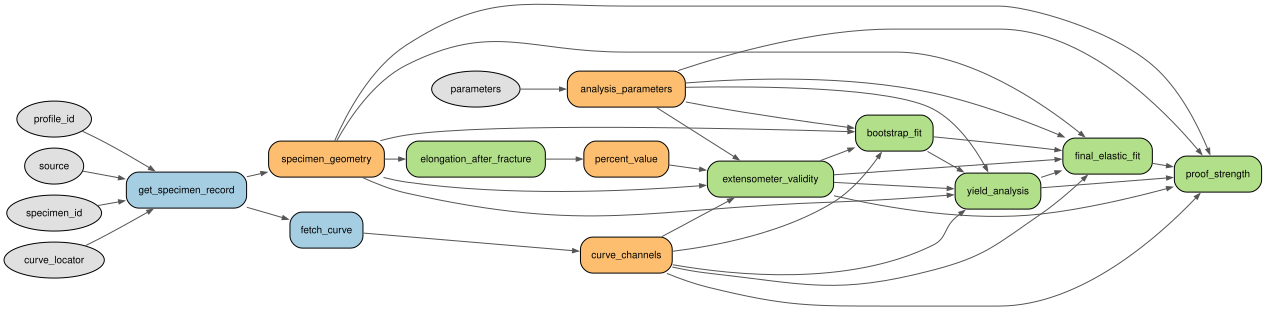

In [17]:
from pmd_tensile.acquisition import fetch_curve, get_specimen_record
from pmd_tensile.analysis import (
    bootstrap_fit,
    elongation_after_fracture,
    extensometer_validity,
    final_elastic_fit,
    proof_strength,
    yield_analysis,
)
from pmd_tensile.workflows import analysis_parameters, curve_channels, percent_value, specimen_geometry


@fr.workflow
def modulus_and_proof_strength(
    profile_id: str, source: dict, specimen_id: str, curve_locator: dict | None = None, parameters: dict | None = None
):
    params = analysis_parameters(parameters)
    record = get_specimen_record(profile_id, source, specimen_id, curve_locator)
    curve = fetch_curve(record)
    time_s, crosshead_mm, force_n, strain, curve_sha256, curve_url = curve_channels(curve)
    s0_mm2, measurements_mm2, l0_mm, lu_mm, su_mm2, rate_switch_strain = specimen_geometry(record)
    elongation = elongation_after_fracture(l0_mm, lu_mm)
    a_percent = percent_value(elongation)
    extensometer, k_ext, extensometer_max_valid_strain = extensometer_validity(
        strain, crosshead_mm, l0_mm, a_percent, rate_switch_strain, params
    )
    bootstrap, noise_mpa = bootstrap_fit(force_n, strain, s0_mm2, k_ext, params)
    yielding, yield_type, reh_mpa, rel_mpa = yield_analysis(
        force_n, strain, s0_mm2, k_ext, bootstrap, rate_switch_strain, params
    )
    elastic, e_gpa, strain_origin = final_elastic_fit(force_n, strain, s0_mm2, k_ext, bootstrap, yielding, params)
    proof, rp02_mpa = proof_strength(force_n, strain, s0_mm2, k_ext, elastic, yielding, rate_switch_strain, params)
    return e_gpa, rp02_mpa, curve_sha256


small = modulus_and_proof_strength.flowrep_recipe
print(f"{len(small.nodes)} child nodes (specimen_workflow: {len(macro.nodes)})")
draw_recipe(small, rankdir="LR")

In [18]:
retrieved_at = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
small_run = pwf.node(modulus_and_proof_strength, "zx3_small").run(
    profile_id=PROFILE_ID, source=SOURCE, specimen_id="Zx3"
)
print("Data retrieved:", retrieved_at)
reuse = pd.DataFrame(
    {
        "new workflow": [small_run.outputs.e_gpa, small_run.outputs.rp02_mpa, small_run.outputs.curve_sha256],
        "specimen_workflow": [zx3_default.outputs.e_gpa, zx3_default.outputs.rp02_mpa, zx3_default.outputs.curve_sha256],
    },
    index=["e_gpa", "rp02_mpa", "curve_sha256"],
)
reuse["identical"] = reuse["new workflow"] == reuse["specimen_workflow"]
display(reuse)

Data retrieved: 2026-11-10 00:29:31+01:00


,new workflow,specimen_workflow,identical
e_gpa,200.0756,200.0756,True
rp02_mpa,375.8609,375.8609,True
curve_sha256,d0b3aaa7d4e871ec97ab691667052c1cf32cf05a874470d5683948ca1ca86bd9,d0b3aaa7d4e871ec97ab691667052c1cf32cf05a874470d5683948ca1ca86bd9,True


The new workflow gives exactly the values of the full workflow, because it runs the same imported functions on the same curve bytes. The functions can also be called without any workflow, as in section 1.

## 7. Prepared for a node catalogue (sim_atlas)

[sim_atlas](https://github.com/XzzX/sim_atlas/) catalogues workflow nodes from Python modules. Its collector imports a module and takes every public object whose `__module__` starts with the module's name; a plain function would be catalogued as a node too. `pmd_tensile` is laid out for that: the public modules contain only nodes, macros and the dataclass types they use, and all helpers (builders, graph I/O, the knowledge-graph export) live in `_`-prefixed modules, which notebooks reach through the facade `pmd_tensile.demo`. The listing below applies the collector's module-mode rule to the four node modules:

In [19]:
import dataclasses
import importlib


def kind(value) -> str:
    recipe = getattr(value, "flowrep_recipe", None)
    if isinstance(recipe, fr.schemas.AtomicRecipe):
        return "atomic node"
    if isinstance(recipe, fr.schemas.WorkflowRecipe):
        return "macro"
    if isinstance(value, type) and dataclasses.is_dataclass(value):
        return "dataclass type"
    return "other (would be mistaken for a node or rejected)"


rows = []
for module_name in ("pmd_tensile.exploration", "pmd_tensile.acquisition", "pmd_tensile.analysis", "pmd_tensile.workflows"):
    module = importlib.import_module(module_name)
    for name, value in vars(module).items():
        if inspect.ismodule(value) or name.startswith("_") or not hasattr(value, "__module__"):
            continue
        if value.__module__.startswith(module_name):
            rows.append({"module": module_name, "kind": kind(value)})
collected = pd.DataFrame(rows)
display(pd.crosstab(collected["module"], collected["kind"]))
print("objects of another kind:", int(collected["kind"].str.startswith("other").sum()))
print("helpers re-exported by pmd_tensile.demo come from:",
      sorted({getattr(demo, name).__module__ for name in demo.__all__ if callable(getattr(demo, name))}))

kind,atomic node,dataclass type,macro
module,,,
pmd_tensile.acquisition,3,0,0
pmd_tensile.analysis,18,13,0
pmd_tensile.exploration,2,0,0
pmd_tensile.workflows,9,0,2


objects of another kind: 0
helpers re-exported by pmd_tensile.demo come from: ['pmd_tensile._acquisition', 'pmd_tensile._analysis', 'pmd_tensile._exploration', 'pmd_tensile._knowledge_graph', 'pmd_tensile._orchestration', 'pmd_tensile._parameters', 'pmd_tensile._plotting', 'pmd_tensile._sources']


The test `tests/test_sim_atlas_collection.py` imitates the sim_atlas collector (commit `753205b`) and checks that module mode and filesystem mode collect exactly the expected nodes, macros and dataclass types and no helper, and that importing any module of the package opens no network connection. The nodes have not been uploaded to a sim_atlas instance.

One gap remains: semantikon stores units and quantity kinds as a flat tuple in the type hint's metadata (below), while sim_atlas at that commit reads units only from a dictionary there. A catalogue entry would currently lose the units.

In [20]:
hint = typing.get_type_hints(analysis.engineering_stress, include_extras=True)["force_n"]
print(hint.__metadata__)

(('uri', SemantikonURI('http://qudt.org/vocab/quantitykind/Force'), 'units', 'N'),)


## Summary

- An `@fr.atomic` node is a plain function with a recipe; its units and quantity kinds are in its type hints, and it can be called directly or run as a pyiron_workflow node with identical results (section 1).
- `specimen_workflow` is a flat macro of 24 nodes; three of them are ontology-aware, and the analysis nodes receive no profile ID and no source (section 2).
- The batch is assembled in code, because semantikon cannot yet export loops (semantikon#541); its inputs have no defaults, so `demo.batch_inputs()` builds them (section 4).
- A method parameter is changed through the `parameters` input; for Zx3 only the proof-strength entries changed (section 5).
- A new workflow built from the imported nodes gives identical E and Rp0.2 (section 6).

[Notebook 04](04-tensile-workflow-knowledge-graph.ipynb) exports these workflows and runs as knowledge graphs, validates them, and queries a run together with the data graph.